# SPHEREx CNN 

##  stages (generated by gpt)
1. Define the task and input format 
2. Inspect the ZIP and catalog, count objects, and display a few FITS images
3. Separate objects into training, validation, and test groups
4. Write and inspect preprocessing: image size, invalid pixels, and intensity scaling
5. Build a small CNN and explain each layer
6. Train while plotting training and validation loss
7. Evaluate once on held-out objects and inspect mistakes
8. Save preprocessing settings and weights, then build prediction for the webpage


## Step 1: write down our settings

The category numbers are just IDs. They do not mean that one category is larger than another


In [1]:
from pathlib import Path

# nasa projecto foldero
data_folder = Path('nasa_3')

# these caategories DO NOT Change across time
class_names = ['moving', 'stable', 'variable']
class_to_number = {name: number for number, name in enumerate(class_names)}

# will change ACCORDING TO WHAT the new FITS dataset has
image_size = None  # Determined from actual FITS dimensions during preparation.
random_seed = 42 #42 - 2 reference

print('The task is to predict the catalog category of an object from its images')
print('Category IDs:', class_to_number)
print('Image size will be determined during preparation')

# here we split by object, so its images stay together
train_fraction = 0.70
validation_fraction = 0.15
test_fraction = 0.15
num_epochs = 20


The task is to predict the catalog category of an object from its images
Category IDs: {'moving': 0, 'stable': 1, 'variable': 2}
Image size will be determined during preparation


## Step 2 inspect data


This step lists the available data and displays one observation. no training yet

In [ ]:
# run this once if new pc (rinat)
# %pip install matplotlib


In [2]:
import csv
import io
import zipfile
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits


### Read the catalog

The catalog connects each file to an object and its category
 
We use the actual archive contents to decide whether a file is available, since the
catalog's `file_present` column may describe the full export


In [3]:
catalog_zips = sorted(data_folder.glob('catalogs*.zip'))
raw_zips = sorted(list(data_folder.glob('raw*.zip')) + list(data_folder.glob('fits*.zip')))

if len(catalog_zips) != 1:
    raise ValueError(f'Expected one catalog ZIP in {data_folder}')
if not raw_zips:
    raise FileNotFoundError(f'No raw*.zip or fits*.zip archives in {data_folder}')

with zipfile.ZipFile(catalog_zips[0]) as archive:
    with archive.open('catalogs/metadata.csv') as catalog_file:
        reader = csv.DictReader(io.TextIOWrapper(catalog_file, encoding='utf-8-sig'))
        catalog_rows = list(reader)

# Support both dataset formats and keep the original category for reference.
category_mapping = {'moving_nasa': 'moving', 'variable_nasa': 'variable'}
for row in catalog_rows:
    row['fits_path'] = row.get('fits_path') or row.get('file', '')
    row['object_name'] = row.get('object_name') or row.get('name', '')
    row['qc_status'] = row.get('qc_status') or row.get('status', 'unknown')
    row['original_class'] = row.get('class', '').strip()
    row['class'] = category_mapping.get(row['original_class'], row['original_class'])
    if not row['fits_path'] or not row['object_name'] or row['class'] not in class_names:
        raise ValueError(f'Check catalog path, object name, or class: {row}')

print('Catalog records:', len(catalog_rows))
print('FITS ZIP parts:', len(raw_zips))
print('Original categories:', dict(Counter(row['original_class'] for row in catalog_rows)))


Catalog records: 2240
FITS ZIP parts: 5
Original categories: {'moving_nasa': 72, 'variable_nasa': 48, 'stable': 712, 'variable': 712, 'moving': 696}


### Locate fits

We build a python dictionary that maps a file path to its zip place
This lets us open one FITS file at a time without extracting the whole dataset 

In [4]:
file_locations = {}

for zip_path in raw_zips:
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            if member.is_dir() or not member.filename.lower().endswith('.fits'):
            #чек если заканчивается на фитс, если нет то пропускаем
                continue
            if member.filename in file_locations:
                with zipfile.ZipFile(file_locations[member.filename]) as previous_archive:
                    same_content = previous_archive.read(member.filename) == archive.read(member.filename)
                if not same_content:
                    raise ValueError(f'Conflicting copies of {member.filename}')
                continue  # Count identical copies once.
            file_locations[member.filename] = zip_path
            # добавляем в словарь, где ключ - путь к файлу, а значение - путь к zip архиву, в котором он находится

observations = []
missing_rows = []
seen_paths = set()
object_categories = {}
# тут мы создаем пустые списки и словари для хранения информации о 
# наблюдениях, 
# отсутствующих строках, 
# уже просмотренных путях и 
# категориях объектов

for row in catalog_rows:
    file_path = row['fits_path'].strip()
    if file_path not in file_locations:
        missing_rows.append(row)
        continue
    # в этом фор лупе, мы проходимся по каждой строке в каталоге, потом проверяем, есть ли путь к файлу в дикшионари file_locations
    # если нет, то добавляем эту строку в список missing_rows, которую мы декларировали сверху и продолжаем к следующей строке

    object_name = row['object_name'].strip()
    category = row['class'].strip()
    if not object_name or category not in class_names:
        raise ValueError(f'Check the object name or category for {file_path}.')
    if file_path in seen_paths:
        raise ValueError(f'The catalog lists this FITS path more than once: {file_path}')
    if object_name in object_categories and object_categories[object_name] != category:
        raise ValueError(f'Conflicting categories for {object_name}.')
    # ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    # первый if проверяет, что имя объекта не пустое и категория входит в список class_names
    # второй if проверяет, что путь к файлу не был уже просмотрен
    # третий if проверяет, что если имя объекта уже встречалось, то его категория
    # то есть это все не препроцессинг, а проверка на корректность данных, и чтобы найти в общем фитсы

    seen_paths.add(file_path)
    object_categories[object_name] = category
    observation = dict(row)
    observation.update(fits_path=file_path, object_name=object_name, **{'class': category})
    observations.append(observation)
    # тут мы 
    # добавляем путь к файлу в множество seen_paths, 
    # обновляем словарь object_categories с категорией объекта, 
    # создаем дикшионари observation, который содержит все данные из строки каталога, а также путь к файлу и категорию объекта
    # и добавляем к obsevations 

if not observations:
    raise ValueError('No catalog paths matched the raw archives') 

print('Matched FITS files:', len(observations))
print('Catalog records without a matching file:', len(missing_rows))
print('FITS paths without a matching catalog row:', len(set(file_locations) - seen_paths))
print('Unique objects:', len(object_categories))
# 


Matched FITS files: 2240
Catalog records without a matching file: 0
FITS paths without a matching catalog row: 0
Unique objects: 95


### Count images and objects separately

An object may have several images 
Those images must stay together when we
make the 70/15/15 split


In [5]:
image_counts = Counter(row['class'] for row in observations)
object_counts = Counter(object_categories.values())

for category in class_names:
    print(f'{category:10} {image_counts[category]:4} images, {object_counts[category]:3} objects')

print('QC labels:', dict(Counter(row.get('qc_status', 'unknown') for row in observations)))


moving      768 images,  33 objects
stable      712 images,  30 objects
variable    760 images,  32 objects
QC labels: {'review_needed': 1071, 'structurally_ok': 1169}


### Open one real image

A FITS file can contain several arrays


In [6]:
def load_fits_image(observation):
    file_path = observation['fits_path']
    zip_path = file_locations[file_path]

    with zipfile.ZipFile(zip_path) as archive:
        fits_bytes = archive.read(file_path)

    with fits.open(io.BytesIO(fits_bytes), memmap=False) as hdus:
        image = np.array(hdus['IMAGE'].data, dtype=np.float32, copy=True)
        header = hdus['IMAGE'].header.copy()

# unnecessary if codes BELOW
    if image.ndim != 2:
        raise ValueError(f'IMAGE SHAPE (not 2d) {image.shape}.')
    if not np.isfinite(image).any():
        raise ValueError(f'No finite intensity values in {file_path}.')

    return image, header


Object: Barnards_Star
Catalog category: moving
Image shape: (82, 82)
Finite pixels: 100.0%
Detector: D1
Observation MJD: 60914.21253
Intensity unit: MJy / sr
QC status: review_needed


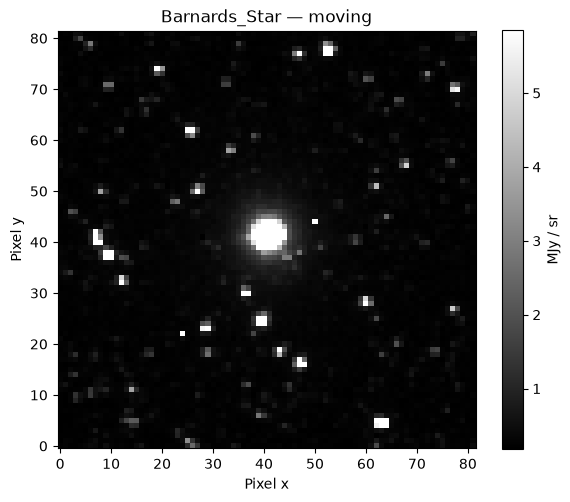

In [7]:
example_index = 0
example = observations[example_index]
image, header = load_fits_image(example)

finite_pixels = image[np.isfinite(image)]
display_min, display_max = np.percentile(finite_pixels, [1, 99])

print('Object:', example['object_name'])
print('Catalog category:', example['class'])
print('Image shape:', image.shape)
print('Finite pixels:', f'{len(finite_pixels) / image.size:.1%}')
print('Detector:', example.get('detector', 'unknown'))
print('Observation MJD:', example.get('mjd', 'unknown'))
print('Intensity unit:', header.get('BUNIT', 'not provided'))
print('QC status:', example.get('qc_status', 'unknown'))

# тут мы порводим через характеристики изображения

fig, ax = plt.subplots(figsize=(6, 5))
display = ax.imshow(image, origin='lower', cmap='gray', vmin=display_min, vmax=display_max)
ax.set_title(f"{example['object_name']} — {example['class']}")
ax.set_xlabel('Pixel x')
ax.set_ylabel('Pixel y')
fig.colorbar(display, ax=ax, label=header.get('BUNIT', 'Intensity'))
plt.tight_layout()
plt.show()


The 1st and 99th percentiles control the display contrast. They do not
change image


## split the objects

Training objects teach the model. Validation objects help us choose the best
checkpoint during the 20 epochs. \

Test objects provide the final evaluation.

We first keep 70% of objects for training. We divide the remaining 30% equally
between validation and testing

`stratify` keeps the category proportions similar

In [8]:
# провалился то покрути опять пип интсалл
from sklearn.model_selection import train_test_split

train_fraction = 0.70
validation_fraction = 0.15
test_fraction = 0.15
num_epochs = 20

object_names = sorted(object_categories)
object_labels = [object_categories[name] for name in object_names]

train_objects, remaining_objects = train_test_split(
    object_names,
    train_size=round(len(object_names) * train_fraction),
    stratify=object_labels,
    random_state=random_seed,
)

remaining_labels = [object_categories[name] for name in remaining_objects]
test_share_of_remaining = test_fraction / (validation_fraction + test_fraction)

validation_objects, test_objects = train_test_split(
    remaining_objects,
    test_size=test_share_of_remaining,
    stratify=remaining_labels,
    random_state=random_seed,
)


### Assign the images


In [9]:
train_object_set = set(train_objects)
validation_object_set = set(validation_objects)
test_object_set = set(test_objects)

train_observations = []
validation_observations = []
test_observations = []

for row in observations:
    object_name = row['object_name']

    if object_name in train_object_set:
        train_observations.append(row)
    elif object_name in validation_object_set:
        validation_observations.append(row)
    elif object_name in test_object_set:
        test_observations.append(row)


# один обьект одна группа
assert train_object_set.isdisjoint(validation_object_set)
assert train_object_set.isdisjoint(test_object_set)
assert validation_object_set.isdisjoint(test_object_set)
assert train_object_set | validation_object_set | test_object_set == set(object_names)
assert len(train_observations) + len(validation_observations) + len(test_observations) == len(observations)

groups = [
    ('Training', train_objects, train_observations),
    ('Validation', validation_objects, validation_observations),
    ('Test', test_objects, test_observations),
]

for group_name, names, rows in groups:
    category_counts = Counter(object_categories[name] for name in names)
    print(f'{group_name}: {len(names)} objects, {len(rows)} images')
    print('  Objects per category:', dict(category_counts))


# Здесь просто, в общем, чек на проблемы, и вывод. не полностью обязательно, но просто переепроверка


Training: 66 objects, 1556 images
  Objects per category: {'moving': 23, 'stable': 21, 'variable': 22}
Validation: 14 objects, 328 images
  Objects per category: {'moving': 5, 'variable': 5, 'stable': 4}
Test: 15 objects, 356 images
  Objects per category: {'moving': 5, 'stable': 5, 'variable': 5}


## Prepare the images

In [10]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(random_seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Training device:', device)


# Read every matched observation once and choose a square that fits them all.
loaded_images = {}
image_shapes = Counter()
for row in observations:
    try:
        image, header = load_fits_image(row)
    except Exception as error:
        raise ValueError(f"Could not read {row['fits_path']}: {error}") from error
    loaded_images[row['fits_path']] = image
    image_shapes[image.shape] += 1

image_size = max(max(shape) for shape in image_shapes)
print('Original image sizes:', dict(image_shapes))
print('Padded input size:', image_size, 'by', image_size)

def pad_channels(normalized, valid):
    """Place the complete image in the center of a zero-filled square."""
    height, width = normalized.shape
    top = (image_size - height) // 2
    left = (image_size - width) // 2
    channels = np.zeros((2, image_size, image_size), dtype=np.float32)
    channels[0, top:top + height, left:left + width] = normalized
    channels[1, top:top + height, left:left + width] = valid
    return channels


def normalize(image):
    """ субстракт фон и делить на уровень шума
    возвращает нормализованный кроп и маску, какие пиксели были реальными"""
    is_real = np.isfinite(image)
    if not is_real.any():
        raise ValueError('The image has no finite pixels')

    real_values = image[is_real]
    background = np.median(real_values)
    noise = 1.4826 * np.median(np.abs(real_values - background))
    noise = max(noise, 1e-8)               # avoid dividing by zero

    normalized = np.zeros(image.shape)      # missing pixels stay 0
    normalized[is_real] = (real_values - background) / noise
    normalized = np.clip(normalized, -10, 10)
    return normalized, is_real


def image_to_channels(image):
    """Normalize original pixels, then add padding and a finite-pixel mask."""
    normalized, is_real = normalize(image.astype(np.float64))
    return pad_channels(normalized, is_real)


def prepare_group(rows):
    """загрузить кропнуть и нормализировать"""
    all_channels = []
    all_labels = []

    for row in rows:
        try:
            image = loaded_images[row['fits_path']]
            all_channels.append(image_to_channels(image))
            all_labels.append(class_to_number[row['class']])
        except Exception as error:
            raise ValueError(f"Could not prepare {row['fits_path']}: {error}") from error

    images = torch.from_numpy(np.stack(all_channels))
    labels = torch.tensor(all_labels, dtype=torch.long)
    return TensorDataset(images, labels)


train_dataset = prepare_group(train_observations)
validation_dataset = prepare_group(validation_observations)
test_dataset = prepare_group(test_observations)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

print('Prepared images:', len(train_dataset), len(validation_dataset), len(test_dataset))
for name, dataset in [('Training', train_dataset), ('Validation', validation_dataset), ('Test', test_dataset)]:
    images, labels = dataset.tensors
    assert torch.isfinite(images).all(), f'{name} contains non-finite values'
    assert images.shape[1:] == (2, image_size, image_size)
    print(name, 'tensor shape:', tuple(images.shape))
assert len(train_dataset) + len(validation_dataset) + len(test_dataset) == len(observations)


Training device: cpu
Original image sizes: {(82, 82): 1948, (81, 82): 10, (82, 83): 5, (80, 82): 6, (82, 62): 4, (82, 42): 4, (63, 82): 4, (82, 58): 2, (60, 82): 5, (48, 82): 5, (65, 82): 4, (82, 50): 1, (82, 54): 4, (77, 82): 3, (82, 51): 3, (82, 56): 3, (82, 71): 1, (82, 73): 1, (70, 82): 3, (82, 47): 4, (82, 43): 4, (82, 57): 4, (82, 45): 2, (82, 41): 4, (82, 55): 2, (62, 82): 7, (74, 41): 1, (51, 82): 4, (52, 82): 6, (82, 44): 2, (73, 82): 5, (66, 82): 5, (55, 82): 10, (82, 75): 1, (79, 82): 3, (76, 82): 5, (82, 76): 2, (57, 82): 4, (50, 82): 7, (82, 53): 3, (54, 82): 2, (38, 82): 4, (82, 80): 4, (69, 82): 2, (44, 82): 3, (73, 55): 1, (82, 49): 2, (82, 81): 11, (53, 82): 4, (56, 82): 5, (72, 82): 2, (61, 82): 2, (40, 82): 1, (82, 78): 3, (74, 82): 4, (45, 82): 3, (82, 61): 3, (67, 82): 7, (64, 82): 7, (83, 82): 2, (36, 82): 3, (78, 82): 3, (39, 82): 3, (49, 82): 5, (82, 84): 2, (82, 68): 3, (42, 82): 4, (83, 84): 1, (82, 48): 2, (59, 82): 2, (82, 63): 1, (82, 69): 1, (68, 82): 6, (

## Build the CNN
Each convolution learns spatial patterns. ReLU adds a nonlinear transformation.
Max pooling reduces image dimensions. Adaptive average pooling summarizes each
feature map. Dropout uses probability 0.25 during training. The final layer
returns three scores, one per category. Cross-entropy loss accepts these scores directly.

`pool_size = 2` keeps a 2×2 grid for each feature map. The classifier can use
where the features appear. Set `pool_size = 1` for the original global pooling
baseline. Both options use the same data split, preprocessing, and epochs.


In [ ]:
# 2 gave the best object-level validation macro F1 in our comparison.
pool_size = 2
torch.manual_seed(random_seed)
shuffle_generator = torch.Generator().manual_seed(random_seed)
train_loader.sampler.generator = shuffle_generator

model = nn.Sequential(
    nn.Conv2d(2, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((pool_size, pool_size)),
    nn.Flatten(),
    nn.Dropout(0.25),
    nn.Linear(32 * pool_size * pool_size, len(class_names)),
).to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.001)
print(model)


## Train for 20 epochs
For each training batch, predict categories, measure error, calculate gradients,
and update weights. Validation runs with dropout disabled after each epoch.
We save the checkpoint with the highest object-level validation macro F1. Lower image-level validation loss breaks ties. Each run gets its own output folder.
Run the model-building cell before this cell when starting a fresh experiment.


In [ ]:
from datetime import datetime
from sklearn.metrics import f1_score, recall_score


def object_predictions(probabilities, rows):
    """Average the image probabilities for each object and choose its class."""
    probabilities_by_object = {}
    for row, scores in zip(rows, probabilities, strict=True):
        name = row['object_name']
        probabilities_by_object.setdefault(name, []).append(scores)

    actual_labels = []
    predicted_labels = []
    for name, scores in probabilities_by_object.items():
        actual_labels.append(class_to_number[object_categories[name]])
        predicted_labels.append(int(np.mean(scores, axis=0).argmax()))
    return actual_labels, predicted_labels


class_ids = list(range(len(class_names)))

num_epochs = 20
run_folder = Path('training_runs') / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
run_folder.mkdir(parents=True, exist_ok=False)
best_validation_f1 = -1.0
best_validation_loss = float('inf')
history = []
object_validation_history = []

for epoch in range(num_epochs):
    model.train()
    training_loss = 0.0
    training_correct = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        scores = model(images)
        loss = loss_function(scores, labels)
        loss.backward()
        optimizer.step()
        training_loss += loss.item() * len(labels)
        training_correct += (scores.argmax(1) == labels).sum().item()

    model.eval()
    validation_loss = 0.0
    validation_correct = 0
    validation_probabilities = []
    with torch.no_grad():
        for images, labels in validation_loader:
            images, labels = images.to(device), labels.to(device)
            scores = model(images)
            validation_loss += loss_function(scores, labels).item() * len(labels)
            validation_probabilities.append(scores.softmax(dim=1).cpu().numpy())
            validation_correct += (scores.argmax(1) == labels).sum().item()

    training_loss /= len(train_dataset)
    validation_loss /= len(validation_dataset)
    history.append([training_loss, validation_loss])
    print(f'Epoch {epoch + 1:02}/{num_epochs} | loss {training_loss:.4f} | val loss {validation_loss:.4f} | train acc {training_correct / len(train_dataset):.1%} | val acc {validation_correct / len(validation_dataset):.1%}')

    actual, predicted = object_predictions(
        np.concatenate(validation_probabilities), validation_observations
    )
    macro_f1 = f1_score(actual, predicted, labels=class_ids, average='macro', zero_division=0)
    recalls = recall_score(actual, predicted, labels=class_ids, average=None, zero_division=0)
    recall_by_class = dict(zip(class_names, recalls.tolist()))
    object_validation_history.append({
        'epoch': epoch + 1,
        'macro_f1': macro_f1,
        'recall_by_class': recall_by_class,
    })
    recall_text = ', '.join(f'{name} {value:.0%}' for name, value in recall_by_class.items())
    print(f'  Validation by object | macro F1 {macro_f1:.3f} | recall {recall_text}')

    if (macro_f1, -validation_loss) > (best_validation_f1, -best_validation_loss):
        best_validation_f1 = macro_f1
        best_validation_loss = validation_loss
        torch.save({
            'model_state': model.state_dict(),
            'class_names': class_names,
            'image_size': image_size,
            'epoch': epoch + 1,
            'pool_size': pool_size,
            'validation_macro_f1': float(macro_f1),
            'preprocessing': 'full image median/MAD, clip [-10,10], centered zero padding, finite mask',
        }, run_folder / 'best_cnn.pt')

import json
run_details = {
    'train_objects': sorted(train_objects),
    'validation_objects': sorted(validation_objects),
    'test_objects': sorted(test_objects),
    'history': history,
    'seed': random_seed,
    'pool_size': pool_size,
    'object_validation_history': object_validation_history,
    'best_validation_macro_f1': best_validation_f1,
}
(run_folder / 'training.json').write_text(json.dumps(run_details, indent=2))
plt.plot(range(1, num_epochs + 1), np.array(history)[:, 0], label='Training')
plt.plot(range(1, num_epochs + 1), np.array(history)[:, 1], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.legend()
plt.show()
print('Saved results to', run_folder)


## Evaluate the saved checkpoint


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

checkpoint = torch.load(run_folder / 'best_cnn.pt', map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model_state'])
model.eval()
probability_batches = []
with torch.no_grad():
    for images, labels in test_loader:
        probabilities = model(images.to(device)).softmax(dim=1)
        probability_batches.append(probabilities.cpu().numpy())
probabilities = np.concatenate(probability_batches)

actual_labels, predicted_labels = object_predictions(probabilities, test_observations)

print(classification_report(actual_labels, predicted_labels, labels=[0, 1, 2], target_names=class_names, zero_division=0))
print('Confusion matrix (actual rows, predicted columns):')
print(confusion_matrix(actual_labels, predicted_labels, labels=[0, 1, 2]))
